# 05 · KPI: Completion Rate

**Author:** Pariya  
**Question:** What share of clients in each group finished the process?

Completion rate = share of clients in each group (Control / Test) who reached the `confirm` step.

## Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load the cleaned data
Reads the 3 cleaned CSV files from `01_data_cleaning.ipynb` (experiment clients only), renames `Variation` to `variation`, and builds `df_clients` (demographics + test group) and `df_web_exp` (web events + test group).

In [2]:
clients_demo = pd.read_csv('cleaned_clients_demographics.csv')
clients_var = pd.read_csv('cleaned_clients_variation.csv')
web_events = pd.read_csv('cleaned_web_events.csv', parse_dates=['date_time'])

clients_var = clients_var.rename(columns={'Variation': 'variation'})

df_clients = clients_var.merge(clients_demo, on='client_id', how='inner')
df_web_exp = web_events.merge(clients_var, on='client_id', how='inner')

In [3]:
df_web_exp.head()

,client_id,visitor_id,visit_id,process_step,date_time,variation
0,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:27:07,Test
1,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:26:51,Test
2,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:19:22,Test
3,9988021,580560515_7732621733,781255054_21935453173_531117,step_2,2017-04-17 15:19:13,Test
4,9988021,580560515_7732621733,781255054_21935453173_531117,step_3,2017-04-17 15:18:04,Test


## 1. Explore the web data

In [6]:
df_web_exp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 317135 entries, 0 to 317134
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   client_id     317135 non-null  int64         
 1   visitor_id    317135 non-null  object        
 2   visit_id      317135 non-null  object        
 3   process_step  317135 non-null  object        
 4   date_time     317135 non-null  datetime64[ns]
 5   variation     317135 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(4)
memory usage: 14.5+ MB


In [7]:
df_web_exp['process_step'].value_counts()

process_step
start      101119
step_1      68186
step_2      56654
step_3      48252
confirm     42924
Name: count, dtype: int64

In [8]:
df_web_exp['variation'].value_counts()

variation
Test       176641
Control    140494
Name: count, dtype: int64

In [9]:
df_web_exp.groupby('variation')['client_id'].nunique()

variation
Control    23527
Test       26961
Name: client_id, dtype: int64

## 2. Completion rate per group

In [10]:
df_confirm = df_web_exp[df_web_exp['process_step']== 'confirm']
df_confirm

,client_id,visitor_id,visit_id,process_step,date_time,variation
8,8320017,39393514_33118319366,960651974_70596002104_312201,confirm,2017-04-05 13:10:05,Test
13,4033851,762728880_76361333336,949661017_22392791362_127391,confirm,2017-04-05 12:29:03,Control
14,4033851,762728880_76361333336,949661017_22392791362_127391,confirm,2017-04-05 12:29:01,Control
15,4033851,762728880_76361333336,949661017_22392791362_127391,confirm,2017-04-05 12:28:52,Control
24,1982004,618934751_10082078917,132494692_73738638511_70823,confirm,2017-04-17 12:02:42,Test
...,...,...,...,...,...,...
317104,6230585,100189756_32488226026,671811152_97876326241_999687,confirm,2017-05-08 09:29:38,Test
317109,4977550,795300798_27713164444,423005536_66563748376_701196,confirm,2017-05-25 15:19:39,Control
317115,6426623,27047012_3402532492,685634090_42070675506_389171,confirm,2017-05-19 05:40:14,Control
317120,433098,5505424_50616523266,773565250_67577573147_389841,confirm,2017-05-13 15:33:04,Control


In [11]:
total_clients = df_web_exp.groupby('variation')['client_id'].nunique()
total_clients

variation
Control    23527
Test       26961
Name: client_id, dtype: int64

In [12]:
confirm_clients = df_confirm.groupby('variation')['client_id'].nunique()
confirm_clients

variation
Control    15429
Test       18682
Name: client_id, dtype: int64

In [13]:
pd.set_option('display.float_format', '{:,.3f}'.format)
completion_rate = confirm_clients /total_clients
completion_rate

variation
Control   0.656
Test      0.693
Name: client_id, dtype: float64

The new design (Test) had a higher completion rate (69.3%) than the old design (Control, 65.6%), an increase of about 3.7 percentage points. We will test whether this difference is statistically significant.

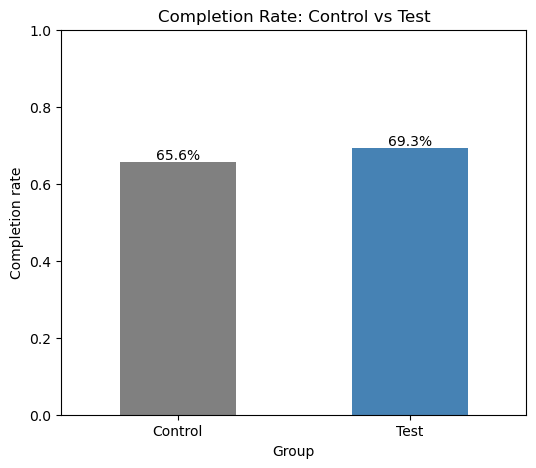

In [14]:
ax = completion_rate.plot(kind='bar', color=['gray', 'steelblue'], figsize=(6, 5))

ax.bar_label(ax.containers[0], labels=[f'{v:.1%}' for v in completion_rate])

plt.title('Completion Rate: Control vs Test')
plt.xlabel('Group')
plt.ylabel('Completion rate')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()